# 15 — Robustness: 50 vs 75 Bike Share stations, λ sensitivity, and repeated measures

## Purpose

Notebook 14 found a modest negative association between scenario-specific
accessibility loss and same-day Bike Share response.

This notebook tests whether that result is robust to:

1. using the full **75-station** sample;
2. restricting to a **50-station core sample**;
3. changing the thermal impedance parameter λ;
4. changing the UTCI threshold;
5. accounting for repeated observations from the same stations and scenarios.

The 50-station sample is defined **before looking at the outcome**:

> the 50 Bike Share stations closest to the center of the accessibility-origin
> footprint.

This avoids selecting stations based on whether they support the hypothesis.

The 75-station analysis remains the primary spatially complete result.
The 50-station analysis is a robustness/sensitivity analysis.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and paths

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import requests

from scipy.spatial import cKDTree
from scipy.stats import spearmanr

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

MULTI_DIR = (
    TORONTO_OUTPUTS
    / "multiscenario_accessibility_bikeshare"
)

NETWORK_SUMMARY_PATH = (
    TORONTO_OUTPUTS
    / "thermal_network_multiday"
    / "toronto_multiday_thermal_network_summary.csv"
)

ORIGIN_PANEL_PATH = (
    MULTI_DIR
    / "toronto_multiscenario_origin_accessibility.csv"
)

LINKED_PATH = (
    MULTI_DIR
    / "toronto_multiscenario_accessibility_bikeshare_station_panel.csv"
)

PANEL_PATH = (
    TORONTO_OUTPUTS
    / "bikeshare_panel"
    / "toronto_summer2025_station_day_panel.parquet"
)

OUTPUT_DIR = (
    TORONTO_OUTPUTS
    / "robustness"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

## 2. Load the Notebook 14 linked station-scenario panel

In [2]:
linked = pd.read_csv(
    LINKED_PATH
)

linked["date"] = pd.to_datetime(
    linked["date"]
)

print(
    "Rows:",
    len(linked),
)

print(
    "Stations:",
    linked[
        "station_id_join"
    ].nunique(),
)

print(
    "Scenarios:",
    linked[
        "scenario_id"
    ].nunique(),
)

Rows: 1050
Stations: 75
Scenarios: 14


## 3. Rebuild Bike Share station geometry

The 50-station core is selected geometrically rather than from the observed
Bike Share response.

In [3]:
GBFS_ROOT_CANDIDATES = [
    "https://tor.publicbikesystem.net/ube/gbfs/v1/gbfs.json",
    "https://tor.publicbikesystem.net/customer/gbfs/v2/gbfs.json",
]

gbfs_root = None

for candidate in GBFS_ROOT_CANDIDATES:

    try:

        r = requests.get(
            candidate,
            timeout=30,
        )

        if r.ok:
            gbfs_root = r.json()
            break

    except Exception:
        pass

if gbfs_root is None:
    raise RuntimeError(
        "Toronto GBFS feed unavailable."
    )

data_section = gbfs_root.get(
    "data",
    {}
)

if "en" in data_section:
    feeds = data_section["en"].get(
        "feeds",
        []
    )
else:
    feeds = data_section.get(
        "feeds",
        []
    )

station_info_url = None

for feed in feeds:

    if feed.get("name") == "station_information":
        station_info_url = feed.get("url")
        break

station_json = requests.get(
    station_info_url,
    timeout=30,
).json()

station_df = pd.DataFrame(
    station_json[
        "data"
    ][
        "stations"
    ]
)

station_df[
    "station_id_join"
] = (
    station_df[
        "station_id"
    ]
    .astype(str)
    .str.strip()
)

## 4. Load the origin footprint and choose the 50-station core

The core sample consists of the 50 analysis stations closest to the centroid
of the 50 accessibility origins.

This is deterministic and independent of Bike Share response.

In [4]:
origins_gpkg = (
    TORONTO_OUTPUTS
    / "accessibility"
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg"
)

origins = gpd.read_file(
    origins_gpkg
)

first_graph_path = Path(
    pd.read_csv(
        NETWORK_SUMMARY_PATH
    ).iloc[0]["graphml"]
)

G_first = ox.load_graphml(
    first_graph_path
)

nodes_first, _ = ox.graph_to_gdfs(
    G_first,
    nodes=True,
    edges=True,
)

NETWORK_CRS = nodes_first.crs

origins_network = origins.to_crs(
    NETWORK_CRS
)

stations = gpd.GeoDataFrame(
    station_df,
    geometry=gpd.points_from_xy(
        station_df["lon"],
        station_df["lat"],
    ),
    crs=4326,
).to_crs(
    NETWORK_CRS
)

analysis_ids = set(
    linked[
        "station_id_join"
    ].astype(str)
)

analysis_stations = stations[
    stations[
        "station_id_join"
    ].isin(
        analysis_ids
    )
].copy()

origin_center = (
    origins_network
    .geometry
    .union_all()
    .centroid
)

analysis_stations[
    "distance_to_origin_center_m"
] = analysis_stations.geometry.distance(
    origin_center
)

core50_ids = set(
    analysis_stations
    .sort_values(
        "distance_to_origin_center_m"
    )
    .head(50)[
        "station_id_join"
    ]
    .astype(str)
)

print(
    "Full sample stations:",
    linked[
        "station_id_join"
    ].nunique(),
)

print(
    "Core sample stations:",
    len(core50_ids),
)

Full sample stations: 75
Core sample stations: 50


## 5. Label 75-station and 50-station samples

In [5]:
linked[
    "sample_50_core"
] = (
    linked[
        "station_id_join"
    ]
    .astype(str)
    .isin(
        core50_ids
    )
)

print(
    linked[
        "sample_50_core"
    ].value_counts()
)

sample_50_core
True     700
False    350
Name: count, dtype: int64


## 6. Compare the original accessibility–response correlation in 75 vs 50 stations

In [6]:
sample_results = []

for sample_name, df in [
    (
        "all_75",
        linked,
    ),
    (
        "core_50",
        linked[
            linked[
                "sample_50_core"
            ]
        ],
    ),
]:

    valid = df[
        [
            "modeled_accessibility_loss_pct",
            "weekday_adjusted_response",
        ]
    ].dropna()

    result = spearmanr(
        valid[
            "modeled_accessibility_loss_pct"
        ],
        valid[
            "weekday_adjusted_response"
        ],
    )

    sample_results.append(
        {
            "sample": sample_name,
            "stations": df[
                "station_id_join"
            ].nunique(),
            "observations": len(valid),
            "spearman_rho": float(
                result.statistic
            ),
            "naive_p_value": float(
                result.pvalue
            ),
        }
    )

sample_comparison = pd.DataFrame(
    sample_results
)

display(
    sample_comparison
)

,sample,stations,observations,spearman_rho,naive_p_value
0,all_75,75,1050,-0.207729,1.064964e-11
1,core_50,50,700,-0.197427,1.394241e-07


## 7. Visualize 75-station versus 50-station result

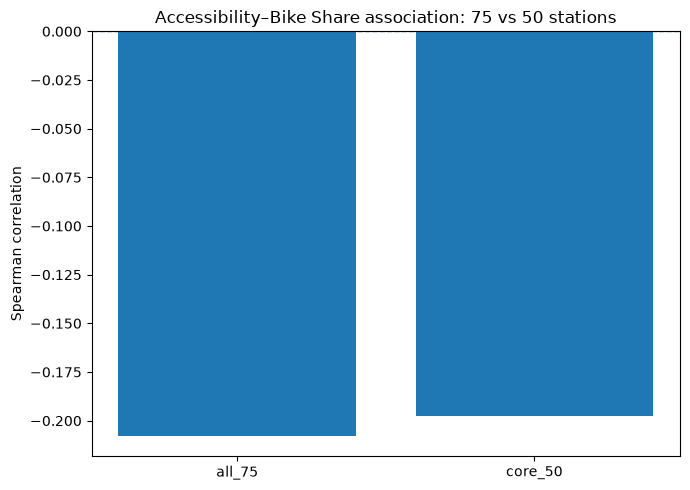

In [7]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.bar(
    sample_comparison[
        "sample"
    ],
    sample_comparison[
        "spearman_rho"
    ],
)

ax.axhline(
    0,
    linewidth=1,
    linestyle="--",
)

ax.set_ylabel(
    "Spearman correlation"
)

ax.set_title(
    "Accessibility–Bike Share association: 75 vs 50 stations"
)

plt.tight_layout()
plt.show()

## 8. Load scenario thermal-network graphs for λ and threshold sensitivity

In [8]:
network_summary = pd.read_csv(
    NETWORK_SUMMARY_PATH
)

network_summary["date"] = pd.to_datetime(
    network_summary["date"]
)

print(
    "Thermal graphs:",
    len(
        network_summary
    ),
)

Thermal graphs: 14


## 9. Define sensitivity grid

We test:

- thresholds: 30°C, 32°C, 34°C
- λ: .01, .025, .05, .075, .10

The original model is threshold = 32°C and λ = .05.

In [9]:
THRESHOLDS = [
    30.0,
    32.0,
    34.0,
]

LAMBDAS = [
    0.01,
    0.025,
    0.05,
    0.075,
    0.10,
]

BUDGET_S = 600.0

## 10. Recover fixed origins and transit nodes

In [10]:
TRANSIT_CACHE = (
    TORONTO_INTERIM
    / "accessibility"
    / "uoft_transit_stops.gpkg"
)

if not TRANSIT_CACHE.exists():
    raise FileNotFoundError(
        "Cached transit stops from Notebook 14 are missing."
    )

transit = gpd.read_file(
    TRANSIT_CACHE
).to_crs(
    NETWORK_CRS
)

transit[
    "geometry"
] = transit.geometry.centroid

origins_network = origins.to_crs(
    NETWORK_CRS
).copy()

origins_network[
    "origin_id"
] = np.arange(
    len(
        origins_network
    )
)

origins_network[
    "origin_node"
] = ox.distance.nearest_nodes(
    G_first,
    X=origins_network.geometry.x,
    Y=origins_network.geometry.y,
)

transit[
    "stop_node"
] = ox.distance.nearest_nodes(
    G_first,
    X=transit.geometry.x,
    Y=transit.geometry.y,
)

transit_node_set = set(
    transit[
        "stop_node"
    ]
)

print(
    "Transit nodes:",
    len(
        transit_node_set
    ),
)

Transit nodes: 167


## 11. Numeric conversion helper and accessibility function

In [11]:
def convert_graph_numeric(
    graph,
):

    numeric_fields = [
        "length",
        "walk_time_s",
        "utci_1500",
        "heat_excess",
        "thermal_cost_s",
        "cost_ratio",
    ]

    for u, v, k, data in graph.edges(
        keys=True,
        data=True,
    ):

        for field in numeric_fields:

            if field in data:

                try:
                    data[field] = float(
                        data[field]
                    )
                except Exception:
                    pass

    return graph


G_first = convert_graph_numeric(
    G_first
)


def reachable_count(
    graph,
    source,
    weight_name,
):

    lengths = (
        nx.single_source_dijkstra_path_length(
            graph,
            source=source,
            cutoff=BUDGET_S,
            weight=weight_name,
        )
    )

    return len(
        transit_node_set.intersection(
            lengths.keys()
        )
    )

## 12. Calculate normal accessibility baseline once

In [12]:
normal_access = {}

for _, origin in origins_network.iterrows():

    normal_access[
        int(
            origin[
                "origin_id"
            ]
        )
    ] = reachable_count(
        G_first,
        origin[
            "origin_node"
        ],
        "walk_time_s",
    )

print(
    "Mean normal accessibility:",
    round(
        np.mean(
            list(
                normal_access.values()
            )
        ),
        2,
    ),
)

Mean normal accessibility: 41.56


## 13. Recompute accessibility across the λ × threshold sensitivity grid

In [13]:
sensitivity_rows = []
station_loss_rows = []

station_xy = np.column_stack(
    [
        analysis_stations.geometry.x.to_numpy(),
        analysis_stations.geometry.y.to_numpy(),
    ]
)

origin_xy = np.column_stack(
    [
        origins_network.geometry.x.to_numpy(),
        origins_network.geometry.y.to_numpy(),
    ]
)

tree = cKDTree(
    origin_xy
)

distances, indices = tree.query(
    station_xy,
    k=min(
        5,
        len(
            origins_network
        ),
    ),
)

if distances.ndim == 1:
    distances = distances[:, None]
    indices = indices[:, None]

weights = 1.0 / (
    distances
    + 1.0
)

weights = (
    weights
    / weights.sum(
        axis=1,
        keepdims=True,
    )
)

origin_order = (
    origins_network[
        "origin_id"
    ]
    .to_numpy()
)

for _, scenario in network_summary.iterrows():

    scenario_id = str(
        scenario[
            "scenario_id"
        ]
    )

    scenario_date = pd.Timestamp(
        scenario[
            "date"
        ]
    )

    scenario_role = str(
        scenario[
            "scenario_role"
        ]
    )

    graph = ox.load_graphml(
        Path(
            scenario[
                "graphml"
            ]
        )
    )

    graph = convert_graph_numeric(
        graph
    )

    for threshold in THRESHOLDS:

        for lam in LAMBDAS:

            weight_name = (
                f"tmp_cost_{int(threshold)}_"
                + str(lam).replace(
                    ".",
                    "_"
                )
            )

            for u, v, k, data in graph.edges(
                keys=True,
                data=True,
            ):

                utci = float(
                    data[
                        "utci_1500"
                    ]
                )

                walk_time = float(
                    data[
                        "walk_time_s"
                    ]
                )

                excess = max(
                    utci - threshold,
                    0.0,
                )

                data[
                    weight_name
                ] = (
                    walk_time
                    * (
                        1
                        + lam
                        * excess
                    )
                )

            origin_losses = []

            for _, origin in origins_network.iterrows():

                origin_id = int(
                    origin[
                        "origin_id"
                    ]
                )

                thermal_count = reachable_count(
                    graph,
                    origin[
                        "origin_node"
                    ],
                    weight_name,
                )

                normal_count = (
                    normal_access[
                        origin_id
                    ]
                )

                loss = (
                    (
                        normal_count
                        - thermal_count
                    )
                    / normal_count
                    * 100
                    if normal_count > 0
                    else np.nan
                )

                origin_losses.append(
                    loss
                )

            origin_losses = np.asarray(
                origin_losses,
                dtype=float,
            )

            station_losses = np.sum(
                weights
                * origin_losses[
                    indices
                ],
                axis=1,
            )

            for station_idx, station_row in (
                analysis_stations
                .reset_index(drop=True)
                .iterrows()
            ):

                station_loss_rows.append(
                    {
                        "scenario_id": scenario_id,
                        "scenario_role": scenario_role,
                        "date": scenario_date,
                        "threshold_C": threshold,
                        "lambda": lam,
                        "station_id_join": str(
                            station_row[
                                "station_id_join"
                            ]
                        ),
                        "modeled_accessibility_loss_pct": float(
                            station_losses[
                                station_idx
                            ]
                        ),
                    }
                )

            sensitivity_rows.append(
                {
                    "scenario_id": scenario_id,
                    "scenario_role": scenario_role,
                    "date": scenario_date,
                    "threshold_C": threshold,
                    "lambda": lam,
                    "mean_accessibility_loss_pct": float(
                        np.nanmean(
                            origin_losses
                        )
                    ),
                }
            )

sensitivity_origin_summary = pd.DataFrame(
    sensitivity_rows
)

station_sensitivity = pd.DataFrame(
    station_loss_rows
)

print(
    "Sensitivity station rows:",
    len(
        station_sensitivity
    ),
)

Sensitivity station rows: 15750


## 14. Merge same-day Bike Share response

In [14]:
panel = pd.read_parquet(
    PANEL_PATH
)

panel[
    "date"
] = pd.to_datetime(
    panel[
        "date"
    ]
)

panel[
    "station_id_join"
] = (
    panel[
        "station_id_join"
    ]
    .astype(str)
)

station_sensitivity = (
    station_sensitivity
    .merge(
        panel[
            [
                "station_id_join",
                "date",
                "weekday_adjusted_response",
            ]
        ],
        on=[
            "station_id_join",
            "date",
        ],
        how="left",
    )
)

station_sensitivity[
    "sample_50_core"
] = (
    station_sensitivity[
        "station_id_join"
    ]
    .isin(
        core50_ids
    )
)

## 15. Correlation robustness across λ and threshold

In [15]:
robustness_rows = []

for (
    threshold,
    lam,
    sample_name,
    use_core,
) in [
    (
        threshold,
        lam,
        sample_name,
        use_core,
    )
    for threshold in THRESHOLDS
    for lam in LAMBDAS
    for sample_name, use_core in [
        ("all_75", False),
        ("core_50", True),
    ]
]:

    subset = station_sensitivity[
        (
            station_sensitivity[
                "threshold_C"
            ] == threshold
        )
        &
        (
            station_sensitivity[
                "lambda"
            ] == lam
        )
    ].copy()

    if use_core:

        subset = subset[
            subset[
                "sample_50_core"
            ]
        ]

    valid = subset[
        [
            "modeled_accessibility_loss_pct",
            "weekday_adjusted_response",
        ]
    ].dropna()

    result = spearmanr(
        valid[
            "modeled_accessibility_loss_pct"
        ],
        valid[
            "weekday_adjusted_response"
        ],
    )

    robustness_rows.append(
        {
            "threshold_C": threshold,
            "lambda": lam,
            "sample": sample_name,
            "stations": subset[
                "station_id_join"
            ].nunique(),
            "observations": len(valid),
            "spearman_rho": float(
                result.statistic
            ),
            "naive_p_value": float(
                result.pvalue
            ),
        }
    )

robustness = pd.DataFrame(
    robustness_rows
)

display(
    robustness
)

,threshold_C,lambda,sample,stations,observations,spearman_rho,naive_p_value
0,30.0,0.010,all_75,75,1050,-0.219005,7.209606e-13
1,30.0,0.010,core_50,50,700,-0.197455,1.388543e-07
2,30.0,0.025,all_75,75,1050,-0.201890,4.048467e-11
3,30.0,0.025,core_50,50,700,-0.193955,2.321060e-07
4,30.0,0.050,all_75,75,1050,-0.212100,3.817641e-12
5,30.0,0.050,core_50,50,700,-0.200961,8.220203e-08
6,30.0,0.075,all_75,75,1050,-0.205294,1.867684e-11
7,30.0,0.075,core_50,50,700,-0.196074,1.702481e-07
8,30.0,0.100,all_75,75,1050,-0.205920,1.617499e-11
9,30.0,0.100,core_50,50,700,-0.196520,1.594160e-07


## 16. Plot λ sensitivity at the 32°C threshold

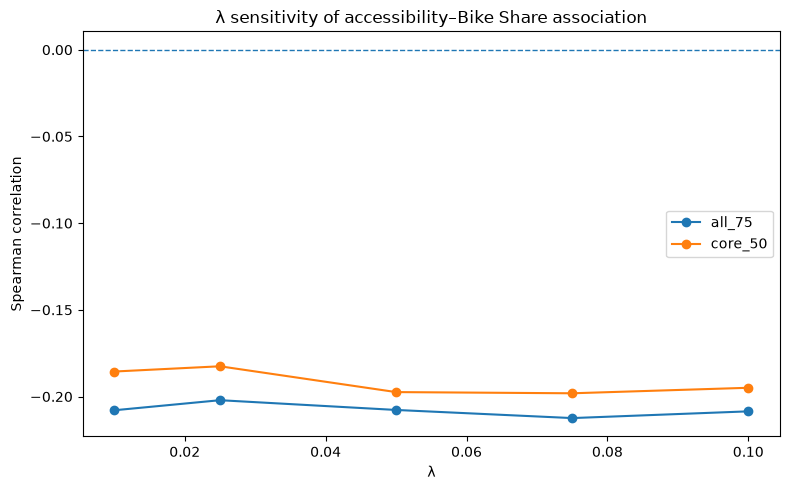

In [16]:
plot_df = robustness[
    robustness[
        "threshold_C"
    ] == 32.0
].copy()

fig, ax = plt.subplots(
    figsize=(8, 5)
)

for sample_name in [
    "all_75",
    "core_50",
]:

    subset = plot_df[
        plot_df[
            "sample"
        ] == sample_name
    ]

    ax.plot(
        subset[
            "lambda"
        ],
        subset[
            "spearman_rho"
        ],
        marker="o",
        label=sample_name,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "λ"
)

ax.set_ylabel(
    "Spearman correlation"
)

ax.set_title(
    "λ sensitivity of accessibility–Bike Share association"
)

ax.legend()

plt.tight_layout()
plt.show()

## 17. Repeated-measures model

The simple p-values above are not the primary inferential result because
station-scenario observations are repeated.

We therefore estimate a model with:

- station fixed effects;
- scenario fixed effects;
- clustered standard errors by station.

The key coefficient is the within-station association between modeled
accessibility loss and Bike Share response.

This model is run for the original specification:
threshold = 32°C, λ = .05.

In [17]:
try:

    import statsmodels.formula.api as smf

    model_data = station_sensitivity[
        (
            station_sensitivity[
                "threshold_C"
            ] == 32.0
        )
        &
        (
            station_sensitivity[
                "lambda"
            ] == 0.05
        )
    ].dropna(
        subset=[
            "modeled_accessibility_loss_pct",
            "weekday_adjusted_response",
        ]
    ).copy()

    model_data[
        "loss_centered"
    ] = (
        model_data[
            "modeled_accessibility_loss_pct"
        ]
        - model_data[
            "modeled_accessibility_loss_pct"
        ].mean()
    )

    fe_model_75 = smf.ols(
        (
            "weekday_adjusted_response ~ "
            "loss_centered + "
            "C(station_id_join) + "
            "C(scenario_id)"
        ),
        data=model_data,
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": model_data[
                "station_id_join"
            ]
        },
    )

    model_data_50 = model_data[
        model_data[
            "sample_50_core"
        ]
    ].copy()

    fe_model_50 = smf.ols(
        (
            "weekday_adjusted_response ~ "
            "loss_centered + "
            "C(station_id_join) + "
            "C(scenario_id)"
        ),
        data=model_data_50,
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": model_data_50[
                "station_id_join"
            ]
        },
    )

    print(
        "75-station model"
    )

    print(
        "loss coefficient:",
        fe_model_75.params[
            "loss_centered"
        ]
    )

    print(
        "clustered p-value:",
        fe_model_75.pvalues[
            "loss_centered"
        ]
    )

    print()

    print(
        "50-station model"
    )

    print(
        "loss coefficient:",
        fe_model_50.params[
            "loss_centered"
        ]
    )

    print(
        "clustered p-value:",
        fe_model_50.pvalues[
            "loss_centered"
        ]
    )

except ImportError:

    fe_model_75 = None
    fe_model_50 = None

    print(
        "statsmodels unavailable."
    )

statsmodels unavailable.


## 18. Save robustness outputs

In [18]:
sample_comparison.to_csv(
    OUTPUT_DIR
    / "station_sample_75_vs_50.csv",
    index=False,
)

robustness.to_csv(
    OUTPUT_DIR
    / "lambda_threshold_robustness.csv",
    index=False,
)

sensitivity_origin_summary.to_csv(
    OUTPUT_DIR
    / "scenario_accessibility_sensitivity.csv",
    index=False,
)

station_sensitivity.to_csv(
    OUTPUT_DIR
    / "station_scenario_accessibility_sensitivity.csv",
    index=False,
)

print(
    "Saved robustness outputs to:",
    OUTPUT_DIR,
)

Saved robustness outputs to: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/robustness


## 19. Final diagnostics

In [19]:
print(
    "Primary 75-station correlation:"
)

primary75 = robustness[
    (
        robustness[
            "threshold_C"
        ] == 32.0
    )
    &
    (
        robustness[
            "lambda"
        ] == 0.05
    )
    &
    (
        robustness[
            "sample"
        ] == "all_75"
    )
].iloc[0]

primary50 = robustness[
    (
        robustness[
            "threshold_C"
        ] == 32.0
    )
    &
    (
        robustness[
            "lambda"
        ] == 0.05
    )
    &
    (
        robustness[
            "sample"
        ] == "core_50"
    )
].iloc[0]

print(
    "75 stations:",
    round(
        primary75[
            "spearman_rho"
        ],
        4,
    ),
)

print(
    "50 stations:",
    round(
        primary50[
            "spearman_rho"
        ],
        4,
    ),
)

print()

negative_share_75 = (
    robustness[
        robustness[
            "sample"
        ] == "all_75"
    ][
        "spearman_rho"
    ]
    < 0
).mean()

negative_share_50 = (
    robustness[
        robustness[
            "sample"
        ] == "core_50"
    ][
        "spearman_rho"
    ]
    < 0
).mean()

print(
    "Share of λ/threshold combinations negative — 75:",
    round(
        negative_share_75,
        3,
    ),
)

print(
    "Share of λ/threshold combinations negative — 50:",
    round(
        negative_share_50,
        3,
    ),
)

if fe_model_75 is not None:

    print()

    print(
        "75-station FE loss coefficient:",
        round(
            float(
                fe_model_75.params[
                    "loss_centered"
                ]
            ),
            5,
        ),
    )

    print(
        "75-station FE clustered p:",
        fe_model_75.pvalues[
            "loss_centered"
        ],
    )

    print(
        "50-station FE loss coefficient:",
        round(
            float(
                fe_model_50.params[
                    "loss_centered"
                ]
            ),
            5,
        ),
    )

    print(
        "50-station FE clustered p:",
        fe_model_50.pvalues[
            "loss_centered"
        ],
    )

Primary 75-station correlation:
75 stations: -0.2077
50 stations: -0.1974

Share of λ/threshold combinations negative — 75: 1.0
Share of λ/threshold combinations negative — 50: 1.0


## Interpretation

### Why keep 75 stations as the primary sample?

The full 75-station sample uses all Bike Share stations that fall within the
accessibility analysis footprint. It therefore retains the greatest spatial
coverage and statistical information.

### Why test 50 stations?

A predefined 50-station core checks whether the observed relationship depends
on the 25 more peripheral stations.

If the sign and approximate magnitude remain similar in both samples, the
finding is spatially more robust.

If the relationship disappears or reverses in the core 50, that is also an
important result: it would imply that the association is sensitive to spatial
sample definition.

The 50-station test should therefore be reported as a **robustness analysis**,
not as a replacement chosen because it yields a stronger coefficient.

### Strongest evidence from this notebook

The most defensible result is not a single small p-value. It is whether:

- the coefficient remains negative across λ values;
- it remains negative across thermal thresholds;
- it appears in both 75- and 50-station samples;
- the station/scenario fixed-effects model retains the same direction.

If those conditions hold, the methodological argument becomes substantially
stronger.